In [132]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [133]:
url = '/Users/javi/Desktop/dsfvfvdv/amz_uk_price_prediction_dataset.csv'
df = pd.read_csv(url)

In [131]:
# Generating a crosstab for 'category' and 'isBestSeller'
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [138]:
# Sort the crosstab result by descending order based on the values of 'True' (Best Sellers)
sorted_crosstab_result = crosstab_result.sort_values(by=True, ascending=False)

# Print the sorted crosstab result
print(sorted_crosstab_result)

#There are no discernable products but Groceries, Health & Personal Care, Power & Hand Tools have around 6% influence not enough to be of any meaning need further investigation

isBestSeller                  False  True 
category                                  
Grocery                        9008    556
Health & Personal Care         9017    552
Baby                          14709    341
Sports & Outdoors            835935    330
Power & Hand Tools             8353    306
...                             ...    ...
Downhill Ski Boots             1284      0
Digital Frames                  774      0
Motorbike Chassis               107      0
Motorbike Drive & Gears         250      0
eBook Readers & Accessories     246      0

[296 rows x 2 columns]


In [126]:
from scipy.stats import chi2_contingency

# Chi-square test for 'category' and 'isBestSeller'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(36540.20270061387, 0.0)

# Interpretation of numbers
there is a very high and even say extreme association between the df['category'] and df['isBestSeller'] 

In [ ]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

# Interpretation of Cramér's V
0.122 suggests quite a weak association between the two variables. Though statistically significant, the strength of this relationship is not very strong in practical terms. 

In [ ]:
# Plotting a stacked bar chart for the 'crosstab_result' data
crosstab_result.plot(kind="bar", stacked=True)

In [134]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

# Apply Tukey's test to identify outliers in the 'price' column
data_series = df['price']  
outliers = tukeys_test_outliers(data_series)

# Create a new DataFrame without outliers
filtered_df = df[~df['price'].isin(outliers)]

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Get the count of each category
category_counts = filtered_df['category'].value_counts()

# Select the top 20 categories
top_20_categories = category_counts.head(20).index

# Filter the DataFrame to include only the top 20 categories
filtered_df_top_20 = filtered_df[filtered_df['category'].isin(top_20_categories)]

# Plotting a violin plot to visualize the distribution of 'price' for each 'category', using the "coolwarm" color palette
sns.violinplot(data=filtered_df_top_20, x='category', y='price', palette="coolwarm")

# Adjust x-axis labels rotation for better readability
plt.xticks(rotation=45, ha='right')

# Show the plot
plt.show()


Best or highest median are = Men, Fragrances and Sports & Outdoors in that order

In [135]:
category_counts = filtered_df['category'].value_counts()

# Select the top 10 categories
top_10_categories = category_counts.head(10).index

# Filter the DataFrame to include only the top 10 categories
filtered_df_top_10 = filtered_df[filtered_df['category'].isin(top_10_categories)]

In [ ]:
# Plotting a bar plot to visualize the average 'price' for each 'category' category, using the "coolwarm" color palette
sns.barplot(data=filtered_df_top_10, x='category', y='price', palette="coolwarm")
plt.xticks(rotation=45, ha='right')

# Show the plot
plt.show()

the highest average price is commanded by Sports & Outdoors

In [136]:
filtered_df_top_10 = filtered_df_top_10[filtered_df_top_10['stars'] > 0]

In [ ]:
# Plotting a box plot to visualize the spread and outliers of 'SalePrice' for each 'MSZoning' category, using the "coolwarm" color palette
sns.boxplot(data=filtered_df_top_10, x='category', y='stars', palette="coolwarm")
plt.xticks(rotation=45, ha='right')

# Show the plot
plt.show()

Handmad Clothing, Shoes & Accessories has the highest median rating


In [137]:
filtered_df_stars_gt_0 = filtered_df[filtered_df['stars'] > 0]

In [ ]:
# Calculating the Pearson correlation coefficient between 'price' and 'stars' columns
correlation = df['price'].corr(df['stars'])
correlation

The Pearson correlation coefficient of -0.1249 suggests a weak negative linear relationship between Amazon prices and the stars of the product. This indicates that there is a slight tendency for products with higher prices to have slightly lower star ratings on Amazon, and vice versa. However, the strength of this relationship is quite weak, implying that other factors may play a more significant role in determining product ratings. Further analysis is required

In [127]:
# Calculating the Pearson correlation coefficient between 'price' and 'stars' columns
correlation = filtered_df_stars_gt_0['price'].corr(filtered_df_stars_gt_0['stars'])
correlation

0.006744508067157907

if we filter the star rating and get rid of the 0 that which sadly in this data frame is counted as a vote eventhough on amazon these votes don't count towards the main result of the real star rating we can see there is almost not correlation between stars and prices

In [128]:
# Calculating the Spearman rank correlation between 'price' and 'stars' 
correlation = df['price'].corr(df['stars'], method='spearman')
correlation

-0.13316425462433876

The Spearman correlation coefficient of -0.1332 indicates a weak negative monotonic relationship between Amazon prices and the stars of the product. This suggests that there is a slight tendency for products with higher prices to have slightly lower star ratings on Amazon, and vice versa, but the relationship is weak. As with the Pearson correlation, this implies that other factors may have a more significant impact on product ratings. Further analysis is requiered

In [129]:
# Calculating the Spearman rank correlation between 'price' and 'stars' 
correlation = filtered_df_stars_gt_0['price'].corr(filtered_df_stars_gt_0['stars'], method='spearman')
correlation

0.024659617205380468

The same stands for the Spearman correlation. There is no direct correlation between price and stars

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

<Axes: xlabel='price', ylabel='stars'>

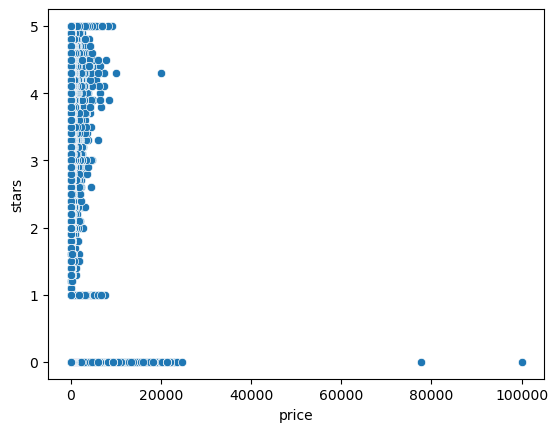

In [130]:
# the entire df Plotting a scatter plot to visualize the relationship between 'stars' and 'price'
sns.scatterplot(data=df, x='price', y='stars')

In [ ]:
# the filtered outliers Plotting a scatter plot to visualize the relationship between 'stars' and 'price'
sns.scatterplot(data=filtered_df, x='price', y='stars')

In [ ]:
# the filtered outliers and 0 stars Plotting a scatter plot to visualize the relationship between 'stars' and 'price'
sns.scatterplot(data=filtered_df_stars_gt_0, x='price', y='stars')

doesn´t matter the price... the reviews are a bit all over the place. Hinting at no correlation between star ratings and prices

In [ ]:
# Separating between discrete and continuous variables, as discrete ones could potentially be treated as categorical.
# Remember to adjust the threshold (in this case, < 20) based on your dataset's specific characteristics and domain knowledge.
potential_categorical_from_numerical = filtered_df_stars_gt_0.select_dtypes("number").loc[:, filtered_df_stars_gt_0.select_dtypes("number").nunique() < 20]
potential_categorical_from_numerical

In [ ]:
df_categorical = pd.concat([filtered_df_stars_gt_0.select_dtypes("object"), potential_categorical_from_numerical], axis=1)

df_numerical = filtered_df_stars_gt_0.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

In [ ]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

In [ ]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(df['price'], line='s');

In [ ]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(filtered_df['price'], line='s');

In [ ]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(filtered_df_stars_gt_0['price'], line='s');

The saleprice is not normally distributed.